# Кластеризация объявлений об аренде

Учебный проект по кластеризации RentHop. Ноутбук применяет K-Means, DBSCAN, агломеративную кластеризацию и Gaussian Mixture к координатам и характеристикам объявлений.

Подготовка данных и команды запуска приведены в [README](../README.md).

## Импорт библиотек

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, deque
from time import perf_counter
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.linear_model import Lasso
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.neighbors import KDTree, kneighbors_graph

## Подготовка объявлений

In [2]:
df_raw = pd.read_json('data/train.json')

print(f'Размер исходного датасета: {df_raw.shape}')

df_raw.head(3)

Размер исходного датасета: (49352, 15)


,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,manager_id,photos,price,street_address,interest_level
4,1.0,1,8579a0b0d54db803821a35a4a615e97a,2016-06-16 05:55:27,Spacious 1 Bedroom 1 Bathroom in Williamsburg!...,145 Borinquen Place,"[Dining Room, Pre-War, Laundry in Building, Di...",40.7108,7170325,-73.9539,a10db4590843d78c784171a107bdacb4,[https://photos.renthop.com/2/7170325_3bb5ac84...,2400,145 Borinquen Place,medium
6,1.0,2,b8e75fc949a6cd8225b455648a951712,2016-06-01 05:44:33,BRAND NEW GUT RENOVATED TRUE 2 BEDROOMFind you...,East 44th,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7513,7092344,-73.9722,955db33477af4f40004820b4aed804a0,[https://photos.renthop.com/2/7092344_7663c19a...,3800,230 East 44th,low
9,1.0,2,cd759a988b8f23924b5a2058d5ab2b49,2016-06-14 15:19:59,**FLEX 2 BEDROOM WITH FULL PRESSURIZED WALL**L...,East 56th Street,"[Doorman, Elevator, Laundry in Building, Laund...",40.7575,7158677,-73.9625,c8b10a317b766204f08e613cef4ce7a0,[https://photos.renthop.com/2/7158677_c897a134...,3495,405 East 56th Street,medium


In [3]:
df_train, df_test = train_test_split(
    df_raw,
    test_size=0.2,
    random_state=21,
    stratify=df_raw['interest_level']
)

df_train = df_train.copy()
df_test = df_test.copy()

print(f'Размер train до обработки: {df_train.shape}')
print(f'Размер test: {df_test.shape}')

Размер train до обработки: (39481, 15)
Размер test: (9871, 15)


In [4]:
q_low = df_train['price'].quantile(0.01)
q_high = df_train['price'].quantile(0.99)

train_size_before = len(df_train)

df_train = df_train.loc[
    df_train['price'].between(q_low, q_high)
].copy()

print(f'Нижняя граница цены: {q_low:.2f}')
print(f'Верхняя граница цены: {q_high:.2f}')
print(f'Удалено объектов из train: {train_size_before - len(df_train)}')
print(f'Осталось объектов в train: {len(df_train)}')

Нижняя граница цены: 1450.00
Верхняя граница цены: 13000.00
Удалено объектов из train: 708
Осталось объектов в train: 38773


In [5]:
def preprocess_interest_level(data):
    data = data.copy()

    interest_mapping = {
        'low': 0,
        'medium': 1,
        'high': 2
    }

    data['interest_level'] = data['interest_level'].map(
        interest_mapping
    )

    return data

df_train = preprocess_interest_level(df_train)
df_test = preprocess_interest_level(df_test)

print(f'Уровни интереса в train:')
print(df_train['interest_level'].value_counts().sort_index())

print(f'Уровни интереса в test:')
print(df_test['interest_level'].value_counts().sort_index())

Уровни интереса в train:
interest_level
0    26978
1     8914
2     2881
Name: count, dtype: int64
Уровни интереса в test:
interest_level
0    6857
1    2246
2     768
Name: count, dtype: int64


In [6]:
for data in [df_train, df_test]:
    data['features_clean'] = data['features'].apply(
        lambda features: [
            feature.replace(' ', '')
            for feature in features
        ]
    )

df_train['features_clean'].head()

25064      [Elevator, CatsAllowed, DogsAllowed, Exclusive]
74277    [Doorman, Elevator, LaundryinBuilding, Dishwas...
95353    [Balcony, Elevator, LaundryinBuilding, Dishwas...
17206    [prewar, elevator, DogsAllowed, CatsAllowed, L...
34671    [RoofDeck, Doorman, Elevator, FitnessCenter, L...
Name: features_clean, dtype: object

In [7]:
all_features = []

for features in df_train['features_clean']:
    all_features.extend(features)

print(f'Первые пять значений: {all_features[:5]}')
print(f'Всего упоминаний удобств: {len(all_features)}')

Первые пять значений: ['Elevator', 'CatsAllowed', 'DogsAllowed', 'Exclusive', 'Doorman']
Всего упоминаний удобств: 210230


In [8]:
counter = Counter(all_features)
top_20 = counter.most_common(20)

amenity_features = [
    feature
    for feature, _ in top_20
]

for data in [df_train, df_test]:
    for feature in amenity_features:
        data[feature] = data['features_clean'].apply(
            lambda features: int(feature in features)
        )

df_train[amenity_features].head()

,Elevator,CatsAllowed,HardwoodFloors,DogsAllowed,Doorman,Dishwasher,NoFee,LaundryinBuilding,FitnessCenter,Pre-War,LaundryinUnit,RoofDeck,OutdoorSpace,DiningRoom,HighSpeedInternet,Balcony,SwimmingPool,LaundryInBuilding,NewConstruction,Terrace
25064,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
74277,1,1,1,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0
95353,1,0,1,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0
17206,0,1,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
34671,1,0,1,0,1,0,1,1,1,0,0,1,0,0,0,0,0,0,0,0


## K-Means

In [9]:
class MyKMeans:
    def __init__(
        self,
        n_clusters=30,
        max_iter=300,
        tol=1e-4,  # Допустимое перемещение центров для остановки
        random_state=21
    ):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state

    def predict(self, X):
        X = np.asarray(X, dtype=float)

        squared_distances = np.sum(
            (X[:, None, :] - self.cluster_centers_[None, :, :]) ** 2,
            axis=2
        )

        return np.argmin(squared_distances, axis=1)

    def fit(self, X):
        X = np.asarray(X, dtype=float)

        if not 1 <= self.n_clusters <= len(X):
            raise ValueError(
                'Число кластеров должно быть от 1 до числа объектов'
            )

        rng = np.random.default_rng(self.random_state)

        center_indices = rng.choice(
            len(X),
            size=self.n_clusters,
            replace=False
        )

        self.cluster_centers_ = X[center_indices].copy()
        self.initial_centers_ = self.cluster_centers_.copy()

        for iteration in range(1, self.max_iter + 1):
            labels = self.predict(X)

            new_centers = self.cluster_centers_.copy()

            for cluster_id in range(self.n_clusters):
                cluster_points = X[labels == cluster_id]

                if len(cluster_points) > 0:
                    new_centers[cluster_id] = cluster_points.mean(axis=0)

            center_shifts = np.linalg.norm(
                new_centers - self.cluster_centers_,
                axis=1
            )

            self.cluster_centers_ = new_centers
            self.n_iter_ = iteration

            if center_shifts.max() <= self.tol:
                break

        self.labels_ = self.predict(X)

        self.inertia_ = np.sum(
            (X - self.cluster_centers_[self.labels_]) ** 2
        )

        return self

In [10]:
coordinate_features = ['longitude', 'latitude']

X_train_coordinates = df_train[coordinate_features].to_numpy()
X_test_coordinates = df_test[coordinate_features].to_numpy()

print(f'Размер train: {X_train_coordinates.shape}')
print(f'Размер test: {X_test_coordinates.shape}')

Размер train: (38773, 2)
Размер test: (9871, 2)


In [11]:
my_kmeans = MyKMeans(
    n_clusters=30,
    max_iter=300,
    tol=1e-4,
    random_state=21
)

start = perf_counter()

my_kmeans.fit(X_train_coordinates)

my_kmeans_fit_time = perf_counter() - start

print(f'Время обучения: {my_kmeans_fit_time:.4f} с')
print(f'Количество итераций: {my_kmeans.n_iter_}')
print(f'Размер массива центров: {my_kmeans.cluster_centers_.shape}')

Время обучения: 0.3016 с
Количество итераций: 37
Размер массива центров: (30, 2)


In [12]:
train_cluster_labels = my_kmeans.predict(X_train_coordinates)
test_cluster_labels = my_kmeans.predict(X_test_coordinates)

print(f'Первые метки train: {train_cluster_labels[:10]}')
print(f'Первые метки test: {test_cluster_labels[:10]}')

print(f'Размер массива меток train: {train_cluster_labels.shape}')
print(f'Размер массива меток test: {test_cluster_labels.shape}')

Первые метки train: [20  7 12 24  9 12 29  7 24 14]
Первые метки test: [ 7 16 22  1 28 17 24  6 27 14]
Размер массива меток train: (38773,)
Размер массива меток test: (9871,)


## Метрики кластеризации

In [13]:
start = perf_counter()

my_kmeans_silhouette = silhouette_score(
    X_train_coordinates,
    train_cluster_labels,
    metric='euclidean'
)

my_kmeans_silhouette_time = perf_counter() - start

my_kmeans_distortion = my_kmeans.inertia_

print(f'Silhouette score: {my_kmeans_silhouette:.4f}')
print(f'Distortion: {my_kmeans_distortion:.4f}')
print(f'Время расчета силуэта: {my_kmeans_silhouette_time:.2f} с')

Silhouette score: 0.3973
Distortion: 25.2589
Время расчета силуэта: 12.70 с


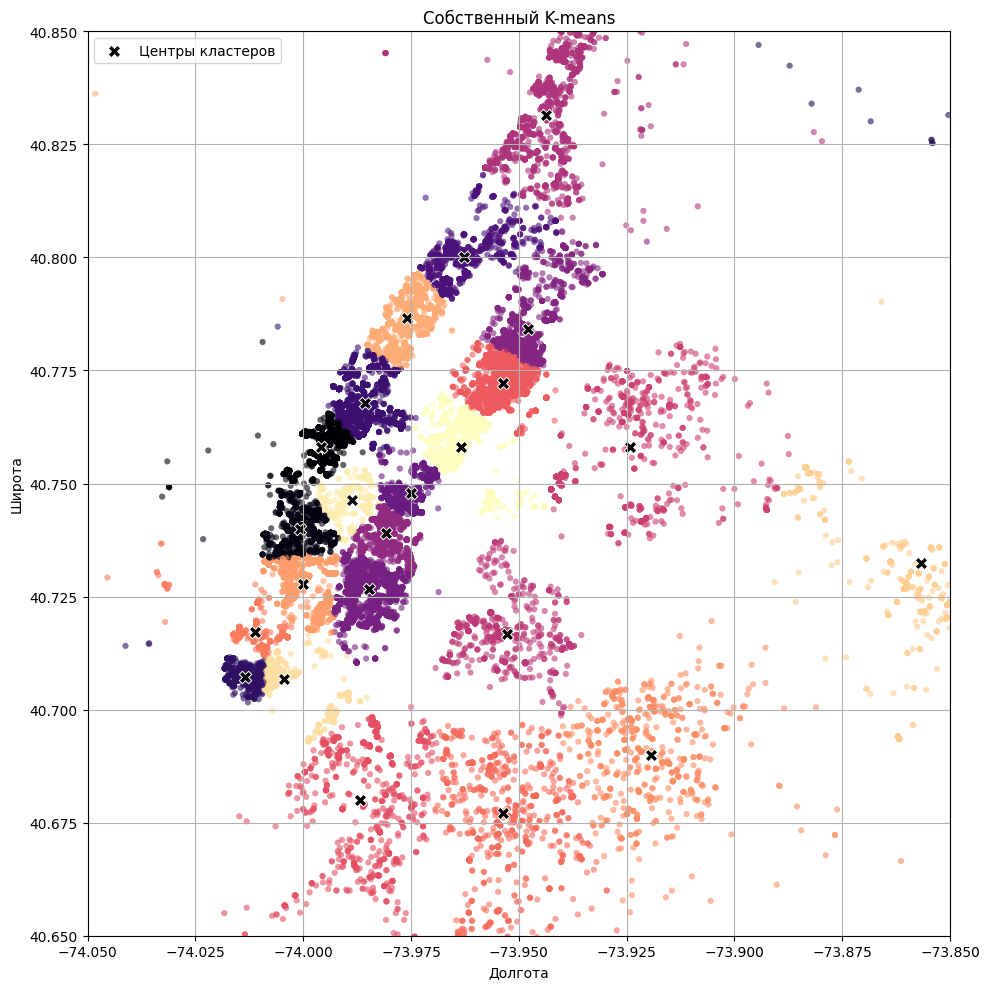

In [16]:
centers = my_kmeans.cluster_centers_

plt.figure(figsize=(10, 10))

sns.scatterplot(
    x=X_train_coordinates[:, 0],
    y=X_train_coordinates[:, 1],
    hue=train_cluster_labels,
    palette='magma',
    s=20,
    alpha=0.6,
    linewidth=0,
    legend=False
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='black',
    marker='X',
    s=80,
    edgecolors='white',
    linewidths=0.7,
    label='Центры кластеров'
)

plt.xlim(-74.05, -73.85)
plt.ylim(40.65, 40.85)

plt.xlabel('Долгота')
plt.ylabel('Широта')
plt.title('Собственный K-means')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Метки кластеров в модели Lasso

In [17]:
lasso_features = [
    'longitude',
    'latitude',
    'bedrooms',
    'bathrooms',
    'interest_level'
] + amenity_features

X_train_lasso = df_train[lasso_features].copy()
X_test_lasso = df_test[lasso_features].copy()

y_train = df_train['price']
y_test = df_test['price']

X_train_lasso['cluster_label'] = train_cluster_labels
X_test_lasso['cluster_label'] = test_cluster_labels

for data in [X_train_lasso, X_test_lasso]:
    for cluster_id in range(my_kmeans.n_clusters):
        feature_name = f'cluster_{cluster_id}'

        data[feature_name] = data['cluster_label'].apply(
            lambda label: int(label == cluster_id)
        )

    data.drop(columns=['cluster_label'], inplace=True)

X_train_lasso.head()

,longitude,latitude,bedrooms,bathrooms,interest_level,Elevator,CatsAllowed,HardwoodFloors,DogsAllowed,Doorman,...,cluster_20,cluster_21,cluster_22,cluster_23,cluster_24,cluster_25,cluster_26,cluster_27,cluster_28,cluster_29
25064,-73.9615,40.6668,1,1.0,0,1,1,0,1,0,...,1,0,0,0,0,0,0,0,0,0
74277,-73.9705,40.7957,1,1.0,0,1,1,1,0,1,...,0,0,0,0,0,0,0,0,0,0
95353,-73.9824,40.7422,2,2.0,1,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
17206,-73.9771,40.7829,1,1.0,0,0,1,0,1,0,...,0,0,0,0,1,0,0,0,0,0
34671,-73.9690,40.7517,2,1.0,0,1,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0


In [18]:
lasso_scaler = MinMaxScaler()

X_train_lasso_scaled = lasso_scaler.fit_transform(X_train_lasso)
X_test_lasso_scaled = lasso_scaler.transform(X_test_lasso)

lasso_kmeans = Lasso(
    alpha=1.0,
    max_iter=10000
)

start = perf_counter()

lasso_kmeans.fit(X_train_lasso_scaled, y_train)

lasso_kmeans_fit_time = perf_counter() - start

print(f'Время обучения Lasso: {lasso_kmeans_fit_time:.4f} с')

Время обучения Lasso: 0.0790 с


In [20]:
lasso_kmeans_train_pred = lasso_kmeans.predict(X_train_lasso_scaled)
lasso_kmeans_test_pred = lasso_kmeans.predict(X_test_lasso_scaled)

In [21]:
lasso_kmeans_train_r2 = r2_score(
    y_train,
    lasso_kmeans_train_pred
)

lasso_kmeans_test_r2 = r2_score(
    y_test,
    lasso_kmeans_test_pred
)

lasso_kmeans_test_mae = mean_absolute_error(
    y_test,
    lasso_kmeans_test_pred
)

print(f'R² на train: {lasso_kmeans_train_r2:.4f}')
print(f'R² на test: {lasso_kmeans_test_r2:.4f}')
print(f'MAE на test: {lasso_kmeans_test_mae:.2f}')

R² на train: 0.6969
R² на test: 0.4561
MAE на test: 697.05


In [23]:
lasso_weights = lasso_kmeans.coef_

lasso_feature_importance = pd.DataFrame({
    'feature': X_train_lasso.columns,
    'weight': lasso_weights
})

lasso_feature_importance['abs_weight'] = (
    lasso_feature_importance['weight'].abs()
)

lasso_feature_importance = lasso_feature_importance.sort_values(
    by='abs_weight'
).reset_index(drop=True)

lasso_feature_importance

,feature,weight,abs_weight
0,longitude,-0.000000,0.000000
1,latitude,0.000000,0.000000
2,CatsAllowed,-0.000000,0.000000
3,NoFee,0.000000,0.000000
4,cluster_0,-0.000000,0.000000
5,cluster_2,-0.000000,0.000000
6,cluster_5,0.000000,0.000000
7,NewConstruction,0.000000,0.000000
8,cluster_13,-0.000000,0.000000
9,cluster_15,0.000000,0.000000


## Сравнение с K-Means из scikit-learn

In [25]:
sklearn_kmeans = KMeans(
    n_clusters=my_kmeans.n_clusters,
    init=my_kmeans.initial_centers_.copy(),
    n_init=1,
    max_iter=my_kmeans.max_iter,
    tol=my_kmeans.tol,
    algorithm='lloyd',
    random_state=21
)

start = perf_counter()

sklearn_kmeans.fit(X_train_coordinates)

sklearn_kmeans_fit_time = perf_counter() - start

print(f'Время обучения sklearn: {sklearn_kmeans_fit_time:.4f} с')

Время обучения sklearn: 0.0479 с


In [26]:
sklearn_train_cluster_labels = sklearn_kmeans.predict(
    X_train_coordinates
)

sklearn_test_cluster_labels = sklearn_kmeans.predict(
    X_test_coordinates
)

sklearn_kmeans_silhouette = silhouette_score(
    X_train_coordinates,
    sklearn_train_cluster_labels,
    metric='euclidean'
)

sklearn_kmeans_distortion = sklearn_kmeans.inertia_

print(f'Silhouette sklearn: {sklearn_kmeans_silhouette:.4f}')
print(f'Distortion sklearn: {sklearn_kmeans_distortion:.4f}')

Silhouette sklearn: 0.3573
Distortion sklearn: 26.8733


In [27]:
kmeans_comparison = pd.DataFrame({
    'model': ['MyKMeans', 'sklearn KMeans'],
    'silhouette': [
        my_kmeans_silhouette,
        sklearn_kmeans_silhouette
    ],
    'distortion': [
        my_kmeans_distortion,
        sklearn_kmeans_distortion
    ],
    'fit_time': [
        my_kmeans_fit_time,
        sklearn_kmeans_fit_time
    ],
    'n_iter': [
        my_kmeans.n_iter_,
        sklearn_kmeans.n_iter_
    ]
})

kmeans_comparison

,model,silhouette,distortion,fit_time,n_iter
0,MyKMeans,0.397317,25.258860,0.301573,37
1,sklearn KMeans,0.357251,26.873299,0.047913,10


## DBSCAN

In [28]:
class MyDBSCAN:
    def __init__(self, eps=0.002, min_samples=10):
        self.eps = eps
        self.min_samples = min_samples

    def _get_neighbors(self, point_index):
        return self.tree_.query_radius(
            self.X_[point_index:point_index + 1],
            r=self.eps
        )[0]

    def fit(self, X):
        self.X_ = np.asarray(X, dtype=float)

        if self.eps <= 0:
            raise ValueError('eps должен быть положительным')

        if self.min_samples < 1:
            raise ValueError('min_samples должен быть не меньше 1')

        self.tree_ = KDTree(self.X_)

        n_samples = len(self.X_)

        self.labels_ = np.full(n_samples, -1, dtype=int)
        visited = np.zeros(n_samples, dtype=bool)
        self.core_mask_ = np.zeros(n_samples, dtype=bool)

        cluster_id = 0

        for point_index in range(n_samples):
            if visited[point_index]:
                continue

            visited[point_index] = True
            neighbors = self._get_neighbors(point_index)

            if len(neighbors) < self.min_samples:
                continue

            self.core_mask_[point_index] = True
            self.labels_[point_index] = cluster_id

            queue = deque(neighbors)
            queued = set(neighbors)

            while queue:
                neighbor_index = queue.popleft()

                if not visited[neighbor_index]:
                    visited[neighbor_index] = True

                    new_neighbors = self._get_neighbors(
                        neighbor_index
                    )

                    if len(new_neighbors) >= self.min_samples:
                        self.core_mask_[neighbor_index] = True

                        for new_index in new_neighbors:
                            if new_index not in queued:
                                queue.append(new_index)
                                queued.add(new_index)

                if self.labels_[neighbor_index] == -1:
                    self.labels_[neighbor_index] = cluster_id

            cluster_id += 1

        self.n_clusters_ = cluster_id
        self.core_points_ = self.X_[self.core_mask_]
        self.core_labels_ = self.labels_[self.core_mask_]

        if len(self.core_points_) > 0:
            self.core_tree_ = KDTree(self.core_points_)
        else:
            self.core_tree_ = None

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        labels = np.full(len(X), -1, dtype=int)

        if self.core_tree_ is None:
            return labels

        distances, indices = self.core_tree_.query(X, k=1)

        distances = distances[:, 0]
        indices = indices[:, 0]

        nearby = distances <= self.eps

        labels[nearby] = self.core_labels_[indices[nearby]]

        return labels

In [31]:
my_dbscan = MyDBSCAN(
    eps=0.002,
    min_samples=10
)

start = perf_counter()

my_dbscan.fit(X_train_coordinates)

my_dbscan_fit_time = perf_counter() - start

print(f'Время обучения DBSCAN: {my_dbscan_fit_time:.4f} с')
print(f'Найдено кластеров: {my_dbscan.n_clusters_}')

Время обучения DBSCAN: 2.4925 с
Найдено кластеров: 130


In [32]:
dbscan_train_labels = my_dbscan.labels_.copy()

print(f'Первые метки train: {dbscan_train_labels[:20]}')
print(f'Размер массива меток train: {dbscan_train_labels.shape}')

Первые метки train: [ 0  1  2  1  2  2  2  1  1  3  3  2  3  1  4  1  5  1  6 -1]
Размер массива меток train: (38773,)


In [33]:
start = perf_counter()

dbscan_test_labels = my_dbscan.predict(X_test_coordinates)

my_dbscan_predict_time = perf_counter() - start

print(f'Первые метки test: {dbscan_test_labels[:20]}')
print(f'Размер массива меток test: {dbscan_test_labels.shape}')
print(f'Время обработки test: {my_dbscan_predict_time:.4f} с')

Первые метки test: [  1 119 125   2   2  -1   1   6   2   3   2   2  27   2   2   2   2   2
   2  -1]
Размер массива меток test: (9871,)
Время обработки test: 0.0266 с


In [34]:
# Смотрим долю шума
train_noise_share = np.mean(dbscan_train_labels == -1)
test_noise_share = np.mean(dbscan_test_labels == -1)

print(f'Доля шума в train: {train_noise_share:.2%}')
print(f'Доля шума в test: {test_noise_share:.2%}')

Доля шума в train: 4.56%
Доля шума в test: 5.10%


In [ ]:
dbscan_cluster_mask = dbscan_train_labels != -1

X_dbscan_clustered = X_train_coordinates[dbscan_cluster_mask]
dbscan_clustered_labels = dbscan_train_labels[dbscan_cluster_mask]

n_clusters = len(np.unique(dbscan_clustered_labels))

if 2 <= n_clusters < len(dbscan_clustered_labels):
    start = perf_counter()

    my_dbscan_silhouette = silhouette_score(
        X_dbscan_clustered,
        dbscan_clustered_labels,
        metric='euclidean'
    )

    silhouette_time = perf_counter() - start

    print(f'Silhouette без шума: {my_dbscan_silhouette:.4f}')
    print(f'Время расчета: {silhouette_time:.2f} с')
else:
    my_dbscan_silhouette = np.nan

    print(f'Для расчета силуэта недостаточно подходящих кластеров')

Silhouette без шума: -0.4439
Время расчета: 12.25 с


In [36]:
my_dbscan_distortion = 0.0

for cluster_id in np.unique(dbscan_clustered_labels):
    cluster_points = X_dbscan_clustered[
        dbscan_clustered_labels == cluster_id
    ]

    cluster_center = cluster_points.mean(axis=0)

    my_dbscan_distortion += np.sum(
        (cluster_points - cluster_center) ** 2
    )

print(f'Distortion без шума: {my_dbscan_distortion:.4f}')

Distortion без шума: 25.7675


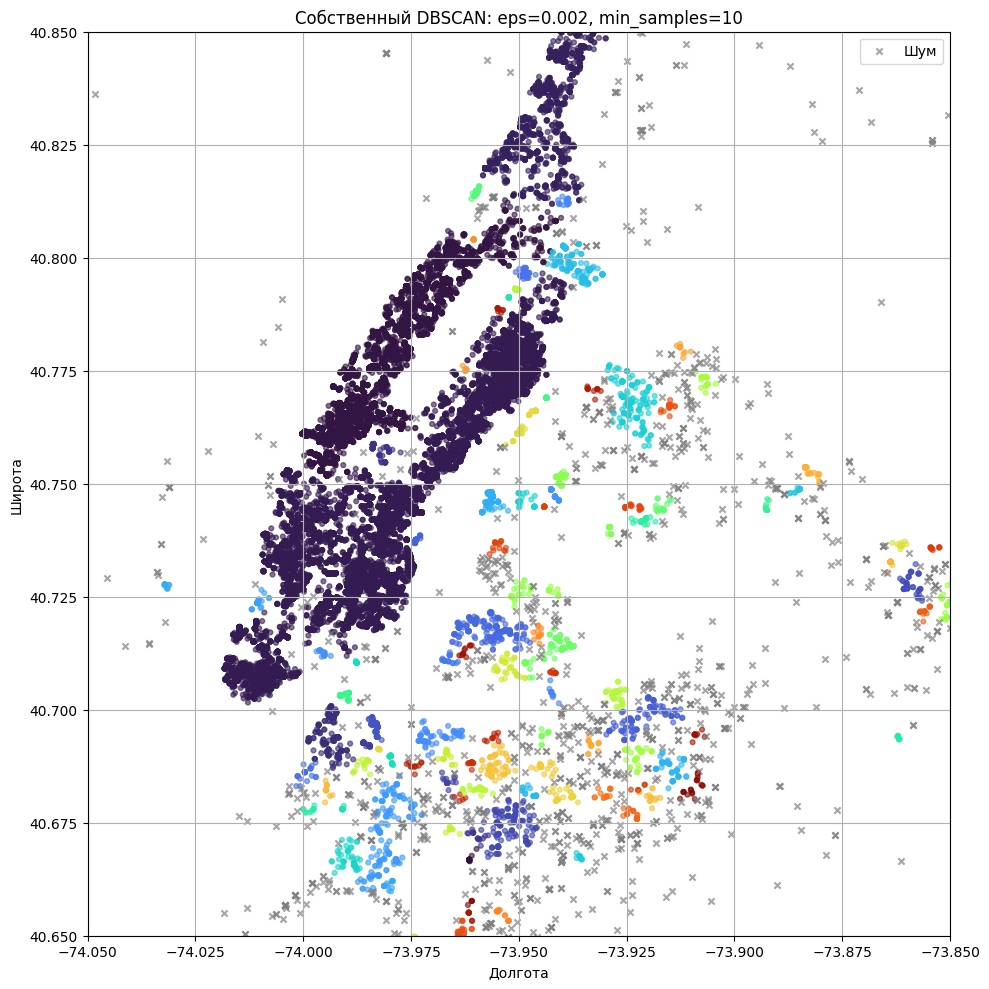

In [37]:
dbscan_noise_mask = dbscan_train_labels == -1
dbscan_cluster_mask = dbscan_train_labels != -1

plt.figure(figsize=(10, 10))

plt.scatter(
    X_train_coordinates[dbscan_cluster_mask, 0],
    X_train_coordinates[dbscan_cluster_mask, 1],
    c=dbscan_train_labels[dbscan_cluster_mask],
    cmap='turbo',
    s=12,
    alpha=0.6
)

plt.scatter(
    X_train_coordinates[dbscan_noise_mask, 0],
    X_train_coordinates[dbscan_noise_mask, 1],
    c='gray',
    marker='x',
    s=20,
    alpha=0.7,
    label='Шум'
)

plt.xlim(-74.05, -73.85)
plt.ylim(40.65, 40.85)

plt.xlabel('Долгота')
plt.ylabel('Широта')
plt.title(
    f'Собственный DBSCAN: eps={my_dbscan.eps}, '
    f'min_samples={my_dbscan.min_samples}'
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [39]:
X_train_lasso_dbscan = df_train[lasso_features].copy()
X_test_lasso_dbscan = df_test[lasso_features].copy()

dbscan_label_values = np.unique(dbscan_train_labels)

train_cluster_features = {}
test_cluster_features = {}

for cluster_id in dbscan_label_values:
    feature_name = f'dbscan_cluster_{cluster_id}'

    train_cluster_features[feature_name] = (
        dbscan_train_labels == cluster_id
    ).astype(int)

    test_cluster_features[feature_name] = (
        dbscan_test_labels == cluster_id
    ).astype(int)

train_cluster_features = pd.DataFrame(
    train_cluster_features,
    index=df_train.index
)

test_cluster_features = pd.DataFrame(
    test_cluster_features,
    index=df_test.index
)

X_train_lasso_dbscan = pd.concat(
    [X_train_lasso_dbscan, train_cluster_features],
    axis=1
)

X_test_lasso_dbscan = pd.concat(
    [X_test_lasso_dbscan, test_cluster_features],
    axis=1
)

print(f'Размер train: {X_train_lasso_dbscan.shape}')
print(f'Размер test: {X_test_lasso_dbscan.shape}')

Размер train: (38773, 156)
Размер test: (9871, 156)


In [40]:
dbscan_lasso_scaler = MinMaxScaler()

X_train_lasso_dbscan_scaled = (
    dbscan_lasso_scaler.fit_transform(X_train_lasso_dbscan)
)

X_test_lasso_dbscan_scaled = (
    dbscan_lasso_scaler.transform(X_test_lasso_dbscan)
)

In [41]:
lasso_dbscan = Lasso(
    alpha=1.0,
    max_iter=10000
)

start = perf_counter()

lasso_dbscan.fit(X_train_lasso_dbscan_scaled, y_train)

lasso_dbscan_fit_time = perf_counter() - start

print(f'Время обучения Lasso: {lasso_dbscan_fit_time:.4f} с')

Время обучения Lasso: 0.1961 с


In [42]:
lasso_dbscan_train_pred = lasso_dbscan.predict(
    X_train_lasso_dbscan_scaled
)

lasso_dbscan_test_pred = lasso_dbscan.predict(
    X_test_lasso_dbscan_scaled
)

lasso_dbscan_train_r2 = r2_score(
    y_train,
    lasso_dbscan_train_pred
)

lasso_dbscan_test_r2 = r2_score(
    y_test,
    lasso_dbscan_test_pred
)

lasso_dbscan_test_mae = mean_absolute_error(
    y_test,
    lasso_dbscan_test_pred
)

print(f'R² на train: {lasso_dbscan_train_r2:.4f}')
print(f'R² на test: {lasso_dbscan_test_r2:.4f}')
print(f'MAE на test: {lasso_dbscan_test_mae:.2f}')

R² на train: 0.6611
R² на test: 0.4383
MAE на test: 742.81


In [48]:
lasso_dbscan_feature_importance = pd.DataFrame({
    'feature': X_train_lasso_dbscan.columns,
    'weight': lasso_dbscan.coef_
})

lasso_dbscan_feature_importance['abs_weight'] = (
    lasso_dbscan_feature_importance['weight'].abs()
)

lasso_dbscan_feature_importance = (
    lasso_dbscan_feature_importance
    .sort_values(by='abs_weight')
    .reset_index(drop=True)
)

pd.set_option('display.max_rows', 40)
pd.set_option('display.min_rows', 30)

lasso_dbscan_feature_importance

,feature,weight,abs_weight
0,longitude,0.000000,0.000000
1,latitude,-0.000000,0.000000
2,CatsAllowed,-0.000000,0.000000
3,Balcony,-0.000000,0.000000
4,dbscan_cluster_0,0.000000,0.000000
5,dbscan_cluster_17,0.000000,0.000000
6,dbscan_cluster_34,-0.000000,0.000000
7,dbscan_cluster_35,-0.000000,0.000000
8,dbscan_cluster_31,-0.000000,0.000000
9,dbscan_cluster_32,-0.000000,0.000000


In [49]:
sklearn_dbscan = DBSCAN(
    eps=my_dbscan.eps,
    min_samples=my_dbscan.min_samples,
    metric='euclidean',
    algorithm='kd_tree',
    n_jobs=2
)

start = perf_counter()

sklearn_dbscan.fit(X_train_coordinates)

sklearn_dbscan_fit_time = perf_counter() - start

sklearn_dbscan_train_labels = sklearn_dbscan.labels_.copy()

print(f'Время обучения sklearn DBSCAN: {sklearn_dbscan_fit_time:.4f} с')

Время обучения sklearn DBSCAN: 0.2450 с


In [50]:
sklearn_dbscan_cluster_mask = sklearn_dbscan_train_labels != -1

sklearn_dbscan_cluster_ids = np.unique(
    sklearn_dbscan_train_labels[sklearn_dbscan_cluster_mask]
)

sklearn_dbscan_n_clusters = len(sklearn_dbscan_cluster_ids)

sklearn_dbscan_noise_share = np.mean(
    sklearn_dbscan_train_labels == -1
)

print(f'Найдено кластеров: {sklearn_dbscan_n_clusters}')
print(f'Доля шума: {sklearn_dbscan_noise_share:.2%}')

Найдено кластеров: 130
Доля шума: 4.56%


In [ ]:
sklearn_dbscan_clustered_X = X_train_coordinates[
    sklearn_dbscan_cluster_mask
]

sklearn_dbscan_clustered_labels = sklearn_dbscan_train_labels[
    sklearn_dbscan_cluster_mask
]

if 2 <= sklearn_dbscan_n_clusters < len(sklearn_dbscan_clustered_labels):
    sklearn_dbscan_silhouette = silhouette_score(
        sklearn_dbscan_clustered_X,
        sklearn_dbscan_clustered_labels,
        metric='euclidean'
    )
else:
    sklearn_dbscan_silhouette = np.nan

In [52]:
sklearn_dbscan_distortion = 0.0

for cluster_id in sklearn_dbscan_cluster_ids:
    cluster_points = sklearn_dbscan_clustered_X[
        sklearn_dbscan_clustered_labels == cluster_id
    ]

    cluster_center = cluster_points.mean(axis=0)

    sklearn_dbscan_distortion += np.sum(
        (cluster_points - cluster_center) ** 2
    )

In [53]:
dbscan_comparison = pd.DataFrame({
    'model': ['MyDBSCAN', 'sklearn DBSCAN'],
    'n_clusters': [
        my_dbscan.n_clusters_,
        sklearn_dbscan_n_clusters
    ],
    'noise_share': [
        np.mean(dbscan_train_labels == -1),
        sklearn_dbscan_noise_share
    ],
    'silhouette': [
        my_dbscan_silhouette,
        sklearn_dbscan_silhouette
    ],
    'distortion': [
        my_dbscan_distortion,
        sklearn_dbscan_distortion
    ],
    'fit_time': [
        my_dbscan_fit_time,
        sklearn_dbscan_fit_time
    ]
})

dbscan_comparison

,model,n_clusters,noise_share,silhouette,distortion,fit_time
0,MyDBSCAN,130,0.045599,-0.443927,25.767477,2.492504
1,sklearn DBSCAN,130,0.045599,-0.443927,25.767477,0.245023


## Агломеративная кластеризация

In [55]:
start = perf_counter()

agglomerative_connectivity = kneighbors_graph(
    X_train_coordinates,
    n_neighbors=20,
    mode='connectivity',
    include_self=False,
    n_jobs=2
)

agglomerative_connectivity = agglomerative_connectivity.maximum(
    agglomerative_connectivity.T
)

agglomerative_graph_time = perf_counter() - start

print(f'Время построения графа: {agglomerative_graph_time:.4f} с')

Время построения графа: 0.1141 с


In [56]:
agglomerative = AgglomerativeClustering(
    n_clusters=30,
    metric='euclidean',
    linkage='ward',
    connectivity=agglomerative_connectivity
)

start = perf_counter()

agglomerative.fit(X_train_coordinates)

agglomerative_fit_time = perf_counter() - start

agglomerative_total_time = (
    agglomerative_graph_time + agglomerative_fit_time
)

agglomerative_train_labels = agglomerative.labels_.copy()

print(f'Время кластеризации: {agglomerative_fit_time:.4f} с')
print(f'Время графа и кластеризации: {agglomerative_total_time:.4f} с')
print(f'Количество кластеров: {len(np.unique(agglomerative_train_labels))}')
print(f'Первые метки train: {agglomerative_train_labels[:10]}')

site-packages/sklearn/cluster/_agglomerative.py:321: UserWarning: the number of connected components of the connectivity matrix is 50 > 1. Completing it to avoid stopping the tree early.
  connectivity, n_connected_components = _fix_connectivity(


Время кластеризации: 5.2154 с
Время графа и кластеризации: 5.3295 с
Количество кластеров: 30
Первые метки train: [ 0 18 20 18  5 29  5  8 18 26]


In [57]:
start = perf_counter()

agglomerative_train_tree = KDTree(X_train_coordinates)

nearest_distances, nearest_indices = agglomerative_train_tree.query(
    X_test_coordinates,
    k=1
)

agglomerative_test_labels = agglomerative_train_labels[
    nearest_indices[:, 0]
]

agglomerative_predict_time = perf_counter() - start

print(f'Первые метки test: {agglomerative_test_labels[:10]}')
print(f'Размер меток train: {agglomerative_train_labels.shape}')
print(f'Размер меток test: {agglomerative_test_labels.shape}')
print(f'Время назначения меток test: {agglomerative_predict_time:.4f} с')

Первые метки test: [18  6 12 13  2  0  4  4 16 26]
Размер меток train: (38773,)
Размер меток test: (9871,)
Время назначения меток test: 0.0206 с


In [58]:
start = perf_counter()

agglomerative_silhouette = silhouette_score(
    X_train_coordinates,
    agglomerative_train_labels,
    metric='euclidean'
)

agglomerative_silhouette_time = perf_counter() - start

print(f'Silhouette score: {agglomerative_silhouette:.4f}')
print(f'Время расчета: {agglomerative_silhouette_time:.2f} с')

Silhouette score: 0.4472
Время расчета: 12.77 с


In [59]:
agglomerative_distortion = 0.0

for cluster_id in np.unique(agglomerative_train_labels):
    cluster_points = X_train_coordinates[
        agglomerative_train_labels == cluster_id
    ]

    cluster_center = cluster_points.mean(axis=0)

    agglomerative_distortion += np.sum(
        (cluster_points - cluster_center) ** 2
    )

print(f'Distortion: {agglomerative_distortion:.4f}')

Distortion: 4.8811


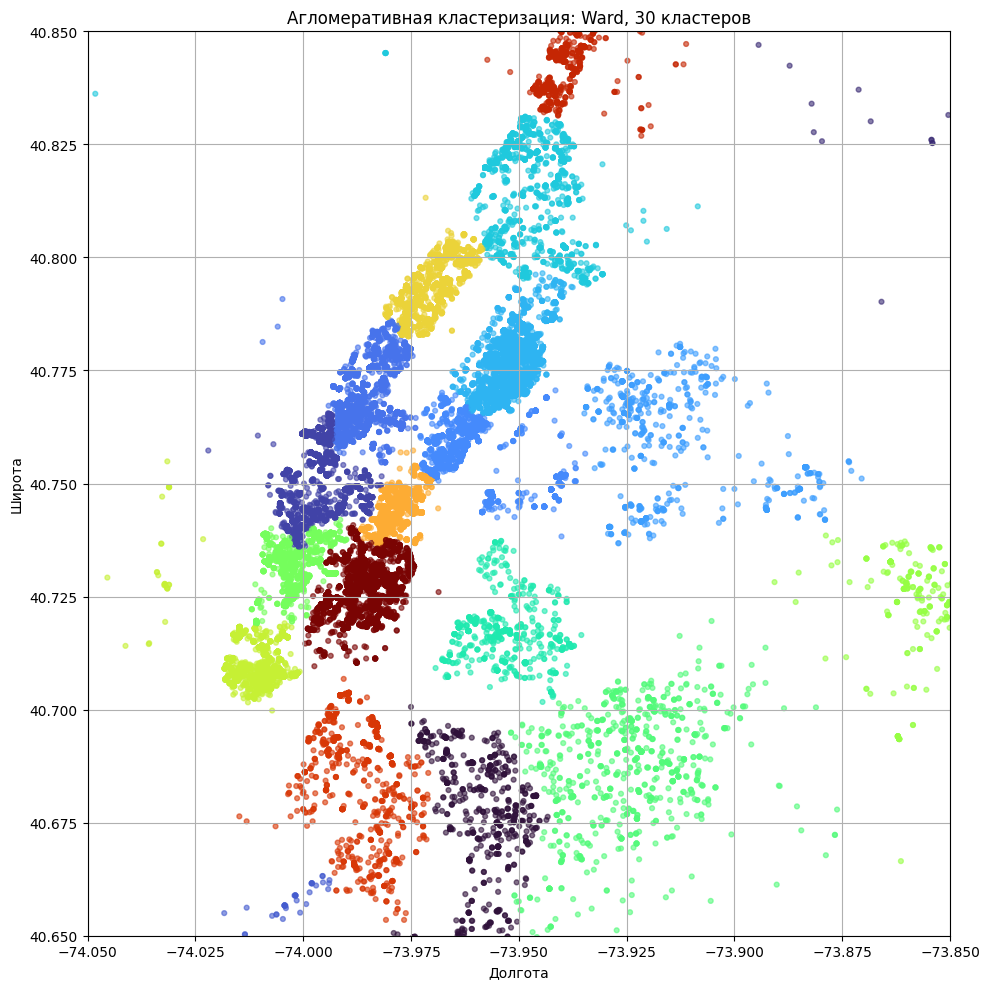

In [60]:
plt.figure(figsize=(10, 10))

plt.scatter(
    X_train_coordinates[:, 0],
    X_train_coordinates[:, 1],
    c=agglomerative_train_labels,
    cmap='turbo',
    s=12,
    alpha=0.6
)

plt.xlim(-74.05, -73.85)
plt.ylim(40.65, 40.85)

plt.xlabel('Долгота')
plt.ylabel('Широта')
plt.title('Агломеративная кластеризация: Ward, 30 кластеров')

plt.grid(True)
plt.tight_layout()
plt.show()

In [61]:
X_train_lasso_agglomerative = df_train[lasso_features].copy()
X_test_lasso_agglomerative = df_test[lasso_features].copy()

y_train = df_train['price']
y_test = df_test['price']

agglomerative_label_values = np.unique(
    agglomerative_train_labels
)

train_cluster_features = {}
test_cluster_features = {}

for cluster_id in agglomerative_label_values:
    feature_name = f'agglomerative_cluster_{cluster_id}'

    train_cluster_features[feature_name] = (
        agglomerative_train_labels == cluster_id
    ).astype(int)

    test_cluster_features[feature_name] = (
        agglomerative_test_labels == cluster_id
    ).astype(int)

train_cluster_features = pd.DataFrame(
    train_cluster_features,
    index=df_train.index
)

test_cluster_features = pd.DataFrame(
    test_cluster_features,
    index=df_test.index
)

X_train_lasso_agglomerative = pd.concat(
    [X_train_lasso_agglomerative, train_cluster_features],
    axis=1
)

X_test_lasso_agglomerative = pd.concat(
    [X_test_lasso_agglomerative, test_cluster_features],
    axis=1
)

print(f'Размер train: {X_train_lasso_agglomerative.shape}')
print(f'Размер test: {X_test_lasso_agglomerative.shape}')

Размер train: (38773, 55)
Размер test: (9871, 55)


In [62]:
agglomerative_lasso_scaler = MinMaxScaler()

X_train_lasso_agglomerative_scaled = (
    agglomerative_lasso_scaler.fit_transform(
        X_train_lasso_agglomerative
    )
)

X_test_lasso_agglomerative_scaled = (
    agglomerative_lasso_scaler.transform(
        X_test_lasso_agglomerative
    )
)

lasso_agglomerative = Lasso(
    alpha=1.0,
    max_iter=10000
)

start = perf_counter()

lasso_agglomerative.fit(
    X_train_lasso_agglomerative_scaled,
    y_train
)

lasso_agglomerative_fit_time = perf_counter() - start

print(f'Время обучения Lasso: {lasso_agglomerative_fit_time:.4f} с')

Время обучения Lasso: 0.0714 с


In [63]:
lasso_agglomerative_train_pred = lasso_agglomerative.predict(
    X_train_lasso_agglomerative_scaled
)

lasso_agglomerative_test_pred = lasso_agglomerative.predict(
    X_test_lasso_agglomerative_scaled
)

lasso_agglomerative_train_r2 = r2_score(
    y_train,
    lasso_agglomerative_train_pred
)

lasso_agglomerative_test_r2 = r2_score(
    y_test,
    lasso_agglomerative_test_pred
)

lasso_agglomerative_test_mae = mean_absolute_error(
    y_test,
    lasso_agglomerative_test_pred
)

print(f'R² на train: {lasso_agglomerative_train_r2:.4f}')
print(f'R² на test: {lasso_agglomerative_test_r2:.4f}')
print(f'MAE на test: {lasso_agglomerative_test_mae:.2f}')

R² на train: 0.6818
R² на test: 0.4515
MAE на test: 715.44


In [64]:
lasso_agglomerative_feature_importance = pd.DataFrame({
    'feature': X_train_lasso_agglomerative.columns,
    'weight': lasso_agglomerative.coef_
})

lasso_agglomerative_feature_importance['abs_weight'] = (
    lasso_agglomerative_feature_importance['weight'].abs()
)

lasso_agglomerative_feature_importance = (
    lasso_agglomerative_feature_importance
    .sort_values(by='abs_weight')
    .reset_index(drop=True)
)

lasso_agglomerative_feature_importance

,feature,weight,abs_weight
0,longitude,-0.000000,0.000000
1,latitude,0.000000,0.000000
2,CatsAllowed,-0.000000,0.000000
3,Balcony,-0.000000,0.000000
4,agglomerative_cluster_28,-0.000000,0.000000
5,agglomerative_cluster_24,-0.000000,0.000000
6,agglomerative_cluster_25,0.000000,0.000000
7,agglomerative_cluster_27,0.000000,0.000000
8,agglomerative_cluster_23,-0.000000,0.000000
9,agglomerative_cluster_15,-0.000000,0.000000


## Gaussian Mixture

In [65]:
gmm = GaussianMixture(
    n_components=30,
    covariance_type='full',
    init_params='kmeans',
    n_init=1,
    max_iter=300,
    tol=1e-3,
    reg_covar=1e-6,
    random_state=21
)

start = perf_counter()

gmm.fit(X_train_coordinates)

gmm_fit_time = perf_counter() - start

print(f'Время обучения GMM: {gmm_fit_time:.4f} с')
print(f'Количество итераций: {gmm.n_iter_}')
print(f'Достигнута сходимость: {gmm.converged_}')

Время обучения GMM: 1.5525 с
Количество итераций: 24
Достигнута сходимость: True


In [66]:
gmm_train_labels = gmm.predict(X_train_coordinates)
gmm_test_labels = gmm.predict(X_test_coordinates)

print(f'Первые метки train: {gmm_train_labels[:10]}')
print(f'Первые метки test: {gmm_test_labels[:10]}')

print(f'Размер меток train: {gmm_train_labels.shape}')
print(f'Размер меток test: {gmm_test_labels.shape}')

Первые метки train: [ 9  0  7 22 27  3 27 19  0  8]
Первые метки test: [ 0 21  6 23 23  9 22 17 13  8]
Размер меток train: (38773,)
Размер меток test: (9871,)


In [67]:
print(f'Задано компонент: {gmm.n_components}')
print(f'Представлено в train: {len(np.unique(gmm_train_labels))}')
print(f'Представлено в test: {len(np.unique(gmm_test_labels))}')

Задано компонент: 30
Представлено в train: 30
Представлено в test: 25


In [68]:
gmm_n_clusters = len(np.unique(gmm_train_labels))

if 2 <= gmm_n_clusters < len(gmm_train_labels):
    start = perf_counter()

    gmm_silhouette = silhouette_score(
        X_train_coordinates,
        gmm_train_labels,
        metric='euclidean'
    )

    gmm_silhouette_time = perf_counter() - start

    print(f'Silhouette score: {gmm_silhouette:.4f}')
    print(f'Время расчета: {gmm_silhouette_time:.2f} с')
else:
    gmm_silhouette = np.nan

    print(f'Для расчета силуэта недостаточно подходящих групп')

Silhouette score: 0.4126
Время расчета: 10.86 с


In [69]:
gmm_distortion = 0.0

for cluster_id in np.unique(gmm_train_labels):
    cluster_points = X_train_coordinates[
        gmm_train_labels == cluster_id
    ]

    cluster_center = cluster_points.mean(axis=0)

    gmm_distortion += np.sum(
        (cluster_points - cluster_center) ** 2
    )

print(f'Distortion: {gmm_distortion:.4f}')

Distortion: 9.6240


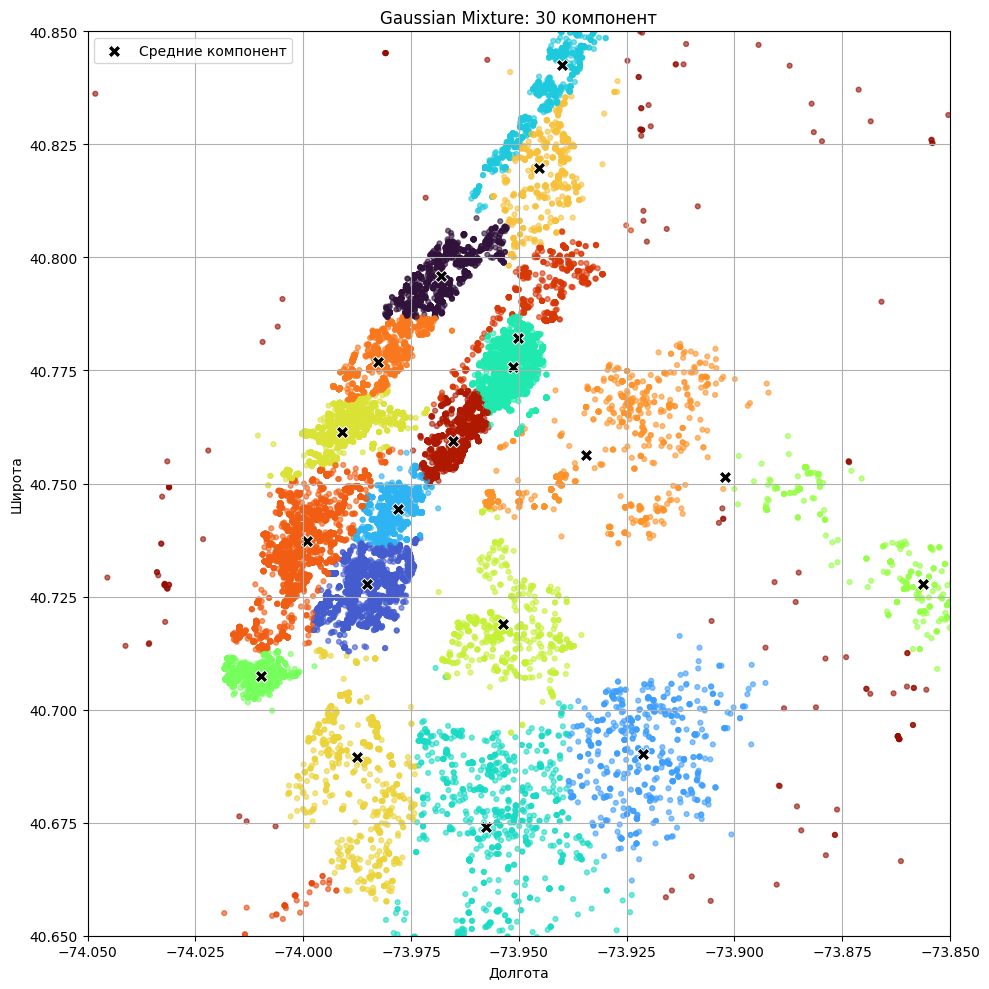

In [70]:
plt.figure(figsize=(10, 10))

plt.scatter(
    X_train_coordinates[:, 0],
    X_train_coordinates[:, 1],
    c=gmm_train_labels,
    cmap='turbo',
    s=12,
    alpha=0.6
)

plt.scatter(
    gmm.means_[:, 0],
    gmm.means_[:, 1],
    c='black',
    marker='X',
    s=80,
    edgecolors='white',
    linewidths=0.7,
    label='Средние компонент'
)

plt.xlim(-74.05, -73.85)
plt.ylim(40.65, 40.85)

plt.xlabel('Долгота')
plt.ylabel('Широта')
plt.title('Gaussian Mixture: 30 компонент')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [71]:
X_train_lasso_gmm = df_train[lasso_features].copy()
X_test_lasso_gmm = df_test[lasso_features].copy()

y_train = df_train['price']
y_test = df_test['price']

train_cluster_features = {}
test_cluster_features = {}

for cluster_id in range(gmm.n_components):
    feature_name = f'gmm_cluster_{cluster_id}'

    train_cluster_features[feature_name] = (
        gmm_train_labels == cluster_id
    ).astype(int)

    test_cluster_features[feature_name] = (
        gmm_test_labels == cluster_id
    ).astype(int)

train_cluster_features = pd.DataFrame(
    train_cluster_features,
    index=df_train.index
)

test_cluster_features = pd.DataFrame(
    test_cluster_features,
    index=df_test.index
)

X_train_lasso_gmm = pd.concat(
    [X_train_lasso_gmm, train_cluster_features],
    axis=1
)

X_test_lasso_gmm = pd.concat(
    [X_test_lasso_gmm, test_cluster_features],
    axis=1
)

print(f'Размер train: {X_train_lasso_gmm.shape}')
print(f'Размер test: {X_test_lasso_gmm.shape}')

Размер train: (38773, 55)
Размер test: (9871, 55)


In [72]:
gmm_lasso_scaler = MinMaxScaler()

X_train_lasso_gmm_scaled = gmm_lasso_scaler.fit_transform(
    X_train_lasso_gmm
)

X_test_lasso_gmm_scaled = gmm_lasso_scaler.transform(
    X_test_lasso_gmm
)

In [73]:
lasso_gmm = Lasso(
    alpha=1.0,
    max_iter=10000
)

start = perf_counter()

lasso_gmm.fit(X_train_lasso_gmm_scaled, y_train)

lasso_gmm_fit_time = perf_counter() - start

print(f'Время обучения Lasso: {lasso_gmm_fit_time:.4f} с')

Время обучения Lasso: 0.0485 с


In [74]:
lasso_gmm_train_pred = lasso_gmm.predict(
    X_train_lasso_gmm_scaled
)

lasso_gmm_test_pred = lasso_gmm.predict(
    X_test_lasso_gmm_scaled
)

lasso_gmm_train_r2 = r2_score(
    y_train,
    lasso_gmm_train_pred
)

lasso_gmm_test_r2 = r2_score(
    y_test,
    lasso_gmm_test_pred
)

lasso_gmm_test_mae = mean_absolute_error(
    y_test,
    lasso_gmm_test_pred
)

print(f'R² на train: {lasso_gmm_train_r2:.4f}')
print(f'R² на test: {lasso_gmm_test_r2:.4f}')
print(f'MAE на test: {lasso_gmm_test_mae:.2f}')

R² на train: 0.6950
R² на test: 0.4536
MAE на test: 700.14


In [75]:
lasso_gmm_feature_importance = pd.DataFrame({
    'feature': X_train_lasso_gmm.columns,
    'weight': lasso_gmm.coef_
})

lasso_gmm_feature_importance['abs_weight'] = (
    lasso_gmm_feature_importance['weight'].abs()
)

lasso_gmm_feature_importance = (
    lasso_gmm_feature_importance
    .sort_values(by='abs_weight')
    .reset_index(drop=True)
)

lasso_gmm_feature_importance

,feature,weight,abs_weight
0,longitude,-0.000000,0.000000
1,latitude,0.000000,0.000000
2,CatsAllowed,-0.000000,0.000000
3,NoFee,0.000000,0.000000
4,gmm_cluster_2,-0.000000,0.000000
5,gmm_cluster_1,-0.000000,0.000000
6,gmm_cluster_5,0.000000,0.000000
7,Balcony,-0.000000,0.000000
8,gmm_cluster_4,-0.000000,0.000000
9,gmm_cluster_29,-0.000000,0.000000


## Кластеризация по характеристикам квартир

In [76]:
clustering_features_3 = [
    'bedrooms',
    'bathrooms',
    'interest_level'
]

X_train_clustering_3 = df_train[clustering_features_3].copy()
X_test_clustering_3 = df_test[clustering_features_3].copy()

X_train_clustering_3.head()

,bedrooms,bathrooms,interest_level
25064,1,1.0,0
74277,1,1.0,0
95353,2,2.0,1
17206,1,1.0,0
34671,2,1.0,0


In [77]:
clustering_scaler_3 = MinMaxScaler()

X_train_clustering_3_scaled = (
    clustering_scaler_3.fit_transform(X_train_clustering_3)
)

X_test_clustering_3_scaled = (
    clustering_scaler_3.transform(X_test_clustering_3)
)

print(f'Размер train: {X_train_clustering_3_scaled.shape}')
print(f'Размер test: {X_test_clustering_3_scaled.shape}')

Размер train: (38773, 3)
Размер test: (9871, 3)


In [78]:
print(f'Диапазоны признаков train:')
print(X_train_clustering_3.agg(['min', 'max']))

unique_combinations = (
    X_train_clustering_3.drop_duplicates().shape[0]
)

print(f'Количество уникальных комбинаций: {unique_combinations}')

Диапазоны признаков train:
     bedrooms  bathrooms  interest_level
min         0        0.0               0
max         8       10.0               2
Количество уникальных комбинаций: 87


In [79]:
my_kmeans_3 = MyKMeans(
    n_clusters=30,
    max_iter=300,
    tol=1e-4,
    random_state=21
)

start = perf_counter()

my_kmeans_3.fit(X_train_clustering_3_scaled)

my_kmeans_3_fit_time = perf_counter() - start

print(f'Время обучения: {my_kmeans_3_fit_time:.4f} с')
print(f'Количество итераций: {my_kmeans_3.n_iter_}')
print(f'Размер массива центров: {my_kmeans_3.cluster_centers_.shape}')

Время обучения: 0.0698 с
Количество итераций: 5
Размер массива центров: (30, 3)


In [80]:
kmeans_3_train_labels = my_kmeans_3.labels_.copy()

kmeans_3_test_labels = my_kmeans_3.predict(
    X_test_clustering_3_scaled
)

print(f'Первые метки train: {kmeans_3_train_labels[:10]}')
print(f'Первые метки test: {kmeans_3_test_labels[:10]}')

print(
    f'Непустых кластеров в train: '
    f'{len(np.unique(kmeans_3_train_labels))}'
)

Первые метки train: [23 23  5 23 15 13 27 23  0  5]
Первые метки test: [ 1 15  2 23  5  2 15 27  2 23]
Непустых кластеров в train: 24


In [81]:
n_clusters_3 = len(np.unique(kmeans_3_train_labels))

if 2 <= n_clusters_3 < len(kmeans_3_train_labels):
    my_kmeans_3_silhouette = silhouette_score(
        X_train_clustering_3_scaled,
        kmeans_3_train_labels,
        metric='euclidean'
    )
else:
    my_kmeans_3_silhouette = np.nan

my_kmeans_3_distortion = my_kmeans_3.inertia_

print(f'Silhouette score: {my_kmeans_3_silhouette:.4f}')
print(f'Distortion: {my_kmeans_3_distortion:.4f}')

Silhouette score: 0.8792
Distortion: 59.2532


In [82]:
X_train_lasso_kmeans_3 = df_train[lasso_features].copy()
X_test_lasso_kmeans_3 = df_test[lasso_features].copy()

y_train = df_train['price']
y_test = df_test['price']

train_cluster_features = {}
test_cluster_features = {}

for cluster_id in range(my_kmeans_3.n_clusters):
    feature_name = f'kmeans_3_cluster_{cluster_id}'

    train_cluster_features[feature_name] = (
        kmeans_3_train_labels == cluster_id
    ).astype(int)

    test_cluster_features[feature_name] = (
        kmeans_3_test_labels == cluster_id
    ).astype(int)

train_cluster_features = pd.DataFrame(
    train_cluster_features,
    index=df_train.index
)

test_cluster_features = pd.DataFrame(
    test_cluster_features,
    index=df_test.index
)

X_train_lasso_kmeans_3 = pd.concat(
    [X_train_lasso_kmeans_3, train_cluster_features],
    axis=1
)

X_test_lasso_kmeans_3 = pd.concat(
    [X_test_lasso_kmeans_3, test_cluster_features],
    axis=1
)

print(f'Размер train: {X_train_lasso_kmeans_3.shape}')
print(f'Размер test: {X_test_lasso_kmeans_3.shape}')

Размер train: (38773, 55)
Размер test: (9871, 55)


In [83]:
kmeans_3_lasso_scaler = MinMaxScaler()

X_train_lasso_kmeans_3_scaled = (
    kmeans_3_lasso_scaler.fit_transform(X_train_lasso_kmeans_3)
)

X_test_lasso_kmeans_3_scaled = (
    kmeans_3_lasso_scaler.transform(X_test_lasso_kmeans_3)
)

lasso_kmeans_3 = Lasso(
    alpha=1.0,
    max_iter=10000
)

start = perf_counter()

lasso_kmeans_3.fit(X_train_lasso_kmeans_3_scaled, y_train)

lasso_kmeans_3_fit_time = perf_counter() - start

print(f'Время обучения Lasso: {lasso_kmeans_3_fit_time:.4f} с')

Время обучения Lasso: 0.0694 с


In [84]:
lasso_kmeans_3_train_pred = lasso_kmeans_3.predict(
    X_train_lasso_kmeans_3_scaled
)

lasso_kmeans_3_test_pred = lasso_kmeans_3.predict(
    X_test_lasso_kmeans_3_scaled
)

lasso_kmeans_3_train_r2 = r2_score(
    y_train,
    lasso_kmeans_3_train_pred
)

lasso_kmeans_3_test_r2 = r2_score(
    y_test,
    lasso_kmeans_3_test_pred
)

lasso_kmeans_3_test_mae = mean_absolute_error(
    y_test,
    lasso_kmeans_3_test_pred
)

print(f'R² на train: {lasso_kmeans_3_train_r2:.4f}')
print(f'R² на test: {lasso_kmeans_3_test_r2:.4f}')
print(f'MAE на test: {lasso_kmeans_3_test_mae:.2f}')

R² на train: 0.6289
R² на test: 0.4552
MAE на test: 783.11


In [85]:
lasso_kmeans_3_feature_importance = pd.DataFrame({
    'feature': X_train_lasso_kmeans_3.columns,
    'weight': lasso_kmeans_3.coef_
})

lasso_kmeans_3_feature_importance['abs_weight'] = (
    lasso_kmeans_3_feature_importance['weight'].abs()
)

lasso_kmeans_3_feature_importance = (
    lasso_kmeans_3_feature_importance
    .sort_values(by='abs_weight')
    .reset_index(drop=True)
)

lasso_kmeans_3_feature_importance

,feature,weight,abs_weight
0,longitude,-0.000000,0.000000
1,latitude,-0.000000,0.000000
2,Balcony,-0.000000,0.000000
3,SwimmingPool,0.000000,0.000000
4,kmeans_3_cluster_1,-0.000000,0.000000
5,kmeans_3_cluster_25,-0.000000,0.000000
6,kmeans_3_cluster_20,0.000000,0.000000
7,kmeans_3_cluster_22,0.000000,0.000000
8,kmeans_3_cluster_16,0.000000,0.000000
9,kmeans_3_cluster_17,0.000000,0.000000


In [86]:
my_dbscan_3 = MyDBSCAN(
    eps=0.15,
    min_samples=10
)

start = perf_counter()

my_dbscan_3.fit(X_train_clustering_3_scaled)

my_dbscan_3_fit_time = perf_counter() - start

print(f'Время обучения: {my_dbscan_3_fit_time:.4f} с')
print(f'Количество кластеров: {my_dbscan_3.n_clusters_}')

Время обучения: 30.1164 с
Количество кластеров: 3


In [87]:
dbscan_3_train_labels = my_dbscan_3.labels_.copy()

dbscan_3_test_labels = my_dbscan_3.predict(
    X_test_clustering_3_scaled
)

print(f'Первые метки train: {dbscan_3_train_labels[:10]}')
print(f'Первые метки test: {dbscan_3_test_labels[:10]}')

print(f'Размер меток train: {dbscan_3_train_labels.shape}')
print(f'Размер меток test: {dbscan_3_test_labels.shape}')

Первые метки train: [0 0 1 0 0 0 0 0 2 1]
Первые метки test: [0 0 0 0 1 0 0 0 0 0]
Размер меток train: (38773,)
Размер меток test: (9871,)


In [88]:
dbscan_3_train_noise_share = np.mean(
    dbscan_3_train_labels == -1
)

dbscan_3_test_noise_share = np.mean(
    dbscan_3_test_labels == -1
)

print(f'Доля шума в train: {dbscan_3_train_noise_share:.2%}')
print(f'Доля шума в test: {dbscan_3_test_noise_share:.2%}')

Доля шума в train: 0.01%
Доля шума в test: 0.03%


In [89]:
dbscan_3_cluster_mask = dbscan_3_train_labels != -1

X_dbscan_3_clustered = X_train_clustering_3_scaled[
    dbscan_3_cluster_mask
]

dbscan_3_clustered_labels = dbscan_3_train_labels[
    dbscan_3_cluster_mask
]

dbscan_3_cluster_ids = np.unique(dbscan_3_clustered_labels)

if 2 <= len(dbscan_3_cluster_ids) < len(dbscan_3_clustered_labels):
    my_dbscan_3_silhouette = silhouette_score(
        X_dbscan_3_clustered,
        dbscan_3_clustered_labels,
        metric='euclidean'
    )
else:
    my_dbscan_3_silhouette = np.nan

print(f'Silhouette без шума: {my_dbscan_3_silhouette:.4f}')

Silhouette без шума: 0.7002


In [90]:
my_dbscan_3_distortion = 0.0

for cluster_id in dbscan_3_cluster_ids:
    cluster_points = X_dbscan_3_clustered[
        dbscan_3_clustered_labels == cluster_id
    ]

    cluster_center = cluster_points.mean(axis=0)

    my_dbscan_3_distortion += np.sum(
        (cluster_points - cluster_center) ** 2
    )

if len(dbscan_3_cluster_ids) == 0:
    my_dbscan_3_distortion = np.nan

print(f'Distortion без шума: {my_dbscan_3_distortion:.4f}')

Distortion без шума: 809.7425


In [91]:
X_train_lasso_dbscan_3 = df_train[lasso_features].copy()
X_test_lasso_dbscan_3 = df_test[lasso_features].copy()

y_train = df_train['price']
y_test = df_test['price']

dbscan_3_label_values = np.union1d(
    np.unique(dbscan_3_train_labels),
    [-1]
)

train_cluster_features = {}
test_cluster_features = {}

for cluster_id in dbscan_3_label_values:
    feature_name = f'dbscan_3_cluster_{cluster_id}'

    train_cluster_features[feature_name] = (
        dbscan_3_train_labels == cluster_id
    ).astype(int)

    test_cluster_features[feature_name] = (
        dbscan_3_test_labels == cluster_id
    ).astype(int)

train_cluster_features = pd.DataFrame(
    train_cluster_features,
    index=df_train.index
)

test_cluster_features = pd.DataFrame(
    test_cluster_features,
    index=df_test.index
)

X_train_lasso_dbscan_3 = pd.concat(
    [X_train_lasso_dbscan_3, train_cluster_features],
    axis=1
)

X_test_lasso_dbscan_3 = pd.concat(
    [X_test_lasso_dbscan_3, test_cluster_features],
    axis=1
)

print(f'Размер train: {X_train_lasso_dbscan_3.shape}')
print(f'Размер test: {X_test_lasso_dbscan_3.shape}')

Размер train: (38773, 29)
Размер test: (9871, 29)


In [92]:
dbscan_3_lasso_scaler = MinMaxScaler()

X_train_lasso_dbscan_3_scaled = (
    dbscan_3_lasso_scaler.fit_transform(X_train_lasso_dbscan_3)
)

X_test_lasso_dbscan_3_scaled = (
    dbscan_3_lasso_scaler.transform(X_test_lasso_dbscan_3)
)

lasso_dbscan_3 = Lasso(
    alpha=1.0,
    max_iter=10000
)

start = perf_counter()

lasso_dbscan_3.fit(X_train_lasso_dbscan_3_scaled, y_train)

lasso_dbscan_3_fit_time = perf_counter() - start

print(f'Время обучения Lasso: {lasso_dbscan_3_fit_time:.4f} с')

Время обучения Lasso: 0.1322 с


In [93]:
lasso_dbscan_3_train_pred = lasso_dbscan_3.predict(
    X_train_lasso_dbscan_3_scaled
)

lasso_dbscan_3_test_pred = lasso_dbscan_3.predict(
    X_test_lasso_dbscan_3_scaled
)

lasso_dbscan_3_train_r2 = r2_score(
    y_train,
    lasso_dbscan_3_train_pred
)

lasso_dbscan_3_test_r2 = r2_score(
    y_test,
    lasso_dbscan_3_test_pred
)

lasso_dbscan_3_test_mae = mean_absolute_error(
    y_test,
    lasso_dbscan_3_test_pred
)

print(f'R² на train: {lasso_dbscan_3_train_r2:.4f}')
print(f'R² на test: {lasso_dbscan_3_test_r2:.4f}')
print(f'MAE на test: {lasso_dbscan_3_test_mae:.2f}')

R² на train: 0.6050
R² на test: 0.4209
MAE на test: 808.98


In [94]:
lasso_dbscan_3_feature_importance = pd.DataFrame({
    'feature': X_train_lasso_dbscan_3.columns,
    'weight': lasso_dbscan_3.coef_
})

lasso_dbscan_3_feature_importance['abs_weight'] = (
    lasso_dbscan_3_feature_importance['weight'].abs()
)

lasso_dbscan_3_feature_importance = (
    lasso_dbscan_3_feature_importance
    .sort_values(by='abs_weight')
    .reset_index(drop=True)
)

lasso_dbscan_3_feature_importance

,feature,weight,abs_weight
0,longitude,-0.000000,0.000000
1,latitude,0.000000,0.000000
2,CatsAllowed,-0.000000,0.000000
3,interest_level,-0.000000,0.000000
4,dbscan_3_cluster_-1,-0.000000,0.000000
5,dbscan_3_cluster_1,0.000000,0.000000
6,Balcony,-0.000000,0.000000
7,SwimmingPool,0.000000,0.000000
8,Pre-War,-49.969323,49.969323
9,DogsAllowed,49.989848,49.989848


In [95]:
start = perf_counter()

agglomerative_3_connectivity = kneighbors_graph(
    X_train_clustering_3_scaled,
    n_neighbors=20,
    mode='connectivity',
    include_self=False,
    n_jobs=2
)

agglomerative_3_connectivity = (
    agglomerative_3_connectivity.maximum(
        agglomerative_3_connectivity.T
    )
)

agglomerative_3_graph_time = perf_counter() - start

print(f'Время построения графа: {agglomerative_3_graph_time:.4f} с')

Время построения графа: 1.3162 с


In [96]:
agglomerative_3 = AgglomerativeClustering(
    n_clusters=30,
    metric='euclidean',
    linkage='ward',
    connectivity=agglomerative_3_connectivity
)

start = perf_counter()

agglomerative_3.fit(X_train_clustering_3_scaled)

agglomerative_3_fit_time = perf_counter() - start

agglomerative_3_total_time = (
    agglomerative_3_graph_time + agglomerative_3_fit_time
)

agglomerative_3_train_labels = agglomerative_3.labels_.copy()

print(f'Время кластеризации: {agglomerative_3_fit_time:.4f} с')
print(f'Время графа и кластеризации: {agglomerative_3_total_time:.4f} с')
print(
    f'Количество кластеров: '
    f'{len(np.unique(agglomerative_3_train_labels))}'
)

site-packages/sklearn/cluster/_agglomerative.py:321: UserWarning: the number of connected components of the connectivity matrix is 36 > 1. Completing it to avoid stopping the tree early.
  connectivity, n_connected_components = _fix_connectivity(


Время кластеризации: 482.7117 с
Время графа и кластеризации: 484.0279 с
Количество кластеров: 30


In [97]:
agglomerative_3_train_tree = KDTree(
    X_train_clustering_3_scaled
)

nearest_distances_3, nearest_indices_3 = (
    agglomerative_3_train_tree.query(
        X_test_clustering_3_scaled,
        k=1
    )
)

agglomerative_3_test_labels = agglomerative_3_train_labels[
    nearest_indices_3[:, 0]
]

print(f'Первые метки train: {agglomerative_3_train_labels[:10]}')
print(f'Первые метки test: {agglomerative_3_test_labels[:10]}')

Первые метки train: [23 23 11 23  1  5  6 23 14 18]
Первые метки test: [25  1 13 23 18 13  1  6 13 23]


In [98]:
agglomerative_3_n_clusters = len(
    np.unique(agglomerative_3_train_labels)
)

if 2 <= agglomerative_3_n_clusters < len(agglomerative_3_train_labels):
    agglomerative_3_silhouette = silhouette_score(
        X_train_clustering_3_scaled,
        agglomerative_3_train_labels,
        metric='euclidean'
    )
else:
    agglomerative_3_silhouette = np.nan

print(f'Silhouette score: {agglomerative_3_silhouette:.4f}')

Silhouette score: 0.9644


In [99]:
agglomerative_3_distortion = 0.0

for cluster_id in np.unique(agglomerative_3_train_labels):
    cluster_points = X_train_clustering_3_scaled[
        agglomerative_3_train_labels == cluster_id
    ]

    cluster_center = cluster_points.mean(axis=0)

    agglomerative_3_distortion += np.sum(
        (cluster_points - cluster_center) ** 2
    )

print(f'Distortion: {agglomerative_3_distortion:.4f}')

Distortion: 6.1510


In [100]:
X_train_lasso_agglomerative_3 = df_train[lasso_features].copy()
X_test_lasso_agglomerative_3 = df_test[lasso_features].copy()

y_train = df_train['price']
y_test = df_test['price']

agglomerative_3_label_values = np.unique(
    agglomerative_3_train_labels
)

train_cluster_features = {}
test_cluster_features = {}

for cluster_id in agglomerative_3_label_values:
    feature_name = f'agglomerative_3_cluster_{cluster_id}'

    train_cluster_features[feature_name] = (
        agglomerative_3_train_labels == cluster_id
    ).astype(int)

    test_cluster_features[feature_name] = (
        agglomerative_3_test_labels == cluster_id
    ).astype(int)

train_cluster_features = pd.DataFrame(
    train_cluster_features,
    index=df_train.index
)

test_cluster_features = pd.DataFrame(
    test_cluster_features,
    index=df_test.index
)

X_train_lasso_agglomerative_3 = pd.concat(
    [X_train_lasso_agglomerative_3, train_cluster_features],
    axis=1
)

X_test_lasso_agglomerative_3 = pd.concat(
    [X_test_lasso_agglomerative_3, test_cluster_features],
    axis=1
)

print(f'Размер train: {X_train_lasso_agglomerative_3.shape}')
print(f'Размер test: {X_test_lasso_agglomerative_3.shape}')

Размер train: (38773, 55)
Размер test: (9871, 55)


In [101]:
agglomerative_3_lasso_scaler = MinMaxScaler()

X_train_lasso_agglomerative_3_scaled = (
    agglomerative_3_lasso_scaler.fit_transform(
        X_train_lasso_agglomerative_3
    )
)

X_test_lasso_agglomerative_3_scaled = (
    agglomerative_3_lasso_scaler.transform(
        X_test_lasso_agglomerative_3
    )
)

In [102]:
lasso_agglomerative_3 = Lasso(
    alpha=1.0,
    max_iter=10000
)

start = perf_counter()

lasso_agglomerative_3.fit(
    X_train_lasso_agglomerative_3_scaled,
    y_train
)

lasso_agglomerative_3_fit_time = perf_counter() - start

print(f'Время обучения Lasso: {lasso_agglomerative_3_fit_time:.4f} с')

Время обучения Lasso: 0.1222 с


In [103]:
lasso_agglomerative_3_train_pred = lasso_agglomerative_3.predict(
    X_train_lasso_agglomerative_3_scaled
)

lasso_agglomerative_3_test_pred = lasso_agglomerative_3.predict(
    X_test_lasso_agglomerative_3_scaled
)

lasso_agglomerative_3_train_r2 = r2_score(
    y_train,
    lasso_agglomerative_3_train_pred
)

lasso_agglomerative_3_test_r2 = r2_score(
    y_test,
    lasso_agglomerative_3_test_pred
)

lasso_agglomerative_3_test_mae = mean_absolute_error(
    y_test,
    lasso_agglomerative_3_test_pred
)

print(f'R² на train: {lasso_agglomerative_3_train_r2:.4f}')
print(f'R² на test: {lasso_agglomerative_3_test_r2:.4f}')
print(f'MAE на test: {lasso_agglomerative_3_test_mae:.2f}')

R² на train: 0.6306
R² на test: 0.4409
MAE на test: 783.97


In [104]:
lasso_agglomerative_3_feature_importance = pd.DataFrame({
    'feature': X_train_lasso_agglomerative_3.columns,
    'weight': lasso_agglomerative_3.coef_
})

lasso_agglomerative_3_feature_importance['abs_weight'] = (
    lasso_agglomerative_3_feature_importance['weight'].abs()
)

lasso_agglomerative_3_feature_importance = (
    lasso_agglomerative_3_feature_importance
    .sort_values(by='abs_weight')
    .reset_index(drop=True)
)

lasso_agglomerative_3_feature_importance

,feature,weight,abs_weight
0,longitude,-0.000000,0.000000
1,latitude,-0.000000,0.000000
2,Balcony,-0.000000,0.000000
3,SwimmingPool,0.000000,0.000000
4,agglomerative_3_cluster_21,-0.000000,0.000000
5,agglomerative_3_cluster_12,-0.000000,0.000000
6,agglomerative_3_cluster_29,0.000000,0.000000
7,agglomerative_3_cluster_28,0.000000,0.000000
8,agglomerative_3_cluster_26,-0.000000,0.000000
9,agglomerative_3_cluster_25,-0.000000,0.000000


In [105]:
gmm_3 = GaussianMixture(
    n_components=30,
    covariance_type='full',
    init_params='kmeans',
    n_init=1,
    max_iter=300,
    tol=1e-3,
    reg_covar=1e-6,
    random_state=21
)

start = perf_counter()

gmm_3.fit(X_train_clustering_3_scaled)

gmm_3_fit_time = perf_counter() - start

print(f'Время обучения GMM: {gmm_3_fit_time:.4f} с')
print(f'Количество итераций: {gmm_3.n_iter_}')
print(f'Достигнута сходимость: {gmm_3.converged_}')

Время обучения GMM: 0.7518 с
Количество итераций: 8
Достигнута сходимость: True


In [106]:
gmm_3_train_labels = gmm_3.predict(
    X_train_clustering_3_scaled
)

gmm_3_test_labels = gmm_3.predict(
    X_test_clustering_3_scaled
)

print(f'Первые метки train: {gmm_3_train_labels[:10]}')
print(f'Первые метки test: {gmm_3_test_labels[:10]}')

print(f'Размер меток train: {gmm_3_train_labels.shape}')
print(f'Размер меток test: {gmm_3_test_labels.shape}')

print(
    f'Представлено компонент в train: '
    f'{len(np.unique(gmm_3_train_labels))}'
)

Первые метки train: [ 3  3 18  3  7  0  6  3 12  1]
Первые метки test: [23  7  4  3  1  4  7  6  4  3]
Размер меток train: (38773,)
Размер меток test: (9871,)
Представлено компонент в train: 30


In [107]:
gmm_3_n_clusters = len(np.unique(gmm_3_train_labels))

if 2 <= gmm_3_n_clusters < len(gmm_3_train_labels):
    gmm_3_silhouette = silhouette_score(
        X_train_clustering_3_scaled,
        gmm_3_train_labels,
        metric='euclidean'
    )
else:
    gmm_3_silhouette = np.nan

print(f'Silhouette score: {gmm_3_silhouette:.4f}')

Silhouette score: 0.9553


In [108]:
gmm_3_distortion = 0.0

for cluster_id in np.unique(gmm_3_train_labels):
    cluster_points = X_train_clustering_3_scaled[
        gmm_3_train_labels == cluster_id
    ]

    cluster_center = cluster_points.mean(axis=0)

    gmm_3_distortion += np.sum(
        (cluster_points - cluster_center) ** 2
    )

print(f'Distortion: {gmm_3_distortion:.4f}')

Distortion: 29.5802


In [109]:
X_train_lasso_gmm_3 = df_train[lasso_features].copy()
X_test_lasso_gmm_3 = df_test[lasso_features].copy()

y_train = df_train['price']
y_test = df_test['price']

train_cluster_features = {}
test_cluster_features = {}

for cluster_id in range(gmm_3.n_components):
    feature_name = f'gmm_3_cluster_{cluster_id}'

    train_cluster_features[feature_name] = (
        gmm_3_train_labels == cluster_id
    ).astype(int)

    test_cluster_features[feature_name] = (
        gmm_3_test_labels == cluster_id
    ).astype(int)

train_cluster_features = pd.DataFrame(
    train_cluster_features,
    index=df_train.index
)

test_cluster_features = pd.DataFrame(
    test_cluster_features,
    index=df_test.index
)

X_train_lasso_gmm_3 = pd.concat(
    [X_train_lasso_gmm_3, train_cluster_features],
    axis=1
)

X_test_lasso_gmm_3 = pd.concat(
    [X_test_lasso_gmm_3, test_cluster_features],
    axis=1
)

print(f'Размер train: {X_train_lasso_gmm_3.shape}')
print(f'Размер test: {X_test_lasso_gmm_3.shape}')

Размер train: (38773, 55)
Размер test: (9871, 55)


In [110]:
gmm_3_lasso_scaler = MinMaxScaler()

X_train_lasso_gmm_3_scaled = (
    gmm_3_lasso_scaler.fit_transform(X_train_lasso_gmm_3)
)

X_test_lasso_gmm_3_scaled = (
    gmm_3_lasso_scaler.transform(X_test_lasso_gmm_3)
)

lasso_gmm_3 = Lasso(
    alpha=1.0,
    max_iter=10000
)

start = perf_counter()

lasso_gmm_3.fit(X_train_lasso_gmm_3_scaled, y_train)

lasso_gmm_3_fit_time = perf_counter() - start

print(f'Время обучения Lasso: {lasso_gmm_3_fit_time:.4f} с')

Время обучения Lasso: 0.1186 с


In [111]:
lasso_gmm_3_train_pred = lasso_gmm_3.predict(
    X_train_lasso_gmm_3_scaled
)

lasso_gmm_3_test_pred = lasso_gmm_3.predict(
    X_test_lasso_gmm_3_scaled
)

lasso_gmm_3_train_r2 = r2_score(
    y_train,
    lasso_gmm_3_train_pred
)

lasso_gmm_3_test_r2 = r2_score(
    y_test,
    lasso_gmm_3_test_pred
)

lasso_gmm_3_test_mae = mean_absolute_error(
    y_test,
    lasso_gmm_3_test_pred
)

print(f'R² на train: {lasso_gmm_3_train_r2:.4f}')
print(f'R² на test: {lasso_gmm_3_test_r2:.4f}')
print(f'MAE на test: {lasso_gmm_3_test_mae:.2f}')

R² на train: 0.6327
R² на test: 0.4428
MAE на test: 784.33


In [112]:
lasso_gmm_3_feature_importance = pd.DataFrame({
    'feature': X_train_lasso_gmm_3.columns,
    'weight': lasso_gmm_3.coef_
})

lasso_gmm_3_feature_importance['abs_weight'] = (
    lasso_gmm_3_feature_importance['weight'].abs()
)

lasso_gmm_3_feature_importance = (
    lasso_gmm_3_feature_importance
    .sort_values(by='abs_weight')
    .reset_index(drop=True)
)

lasso_gmm_3_feature_importance

,feature,weight,abs_weight
0,longitude,-0.000000,0.000000
1,latitude,-0.000000,0.000000
2,Balcony,-0.000000,0.000000
3,SwimmingPool,0.000000,0.000000
4,gmm_3_cluster_2,-0.000000,0.000000
5,gmm_3_cluster_5,-0.000000,0.000000
6,gmm_3_cluster_15,0.000000,0.000000
7,gmm_3_cluster_9,0.000000,0.000000
8,gmm_3_cluster_24,-0.000000,0.000000
9,gmm_3_cluster_21,-0.000000,0.000000


## Сравнение алгоритмов

In [113]:
comparison_rows = []

def add_comparison_result(
    algorithm,
    features,
    labels,
    clustering_results,
    lasso_results=None,
    graph_time=0.0
):
    silhouette, distortion, clustering_time = clustering_results

    row = {
        'algorithm': algorithm,
        'features': features,
        'n_clusters': len(np.unique(labels[labels != -1])),
        'noise_percent': np.mean(labels == -1) * 100,
        'silhouette': silhouette,
        'distortion': distortion,
        'graph_time': graph_time,
        'clustering_fit_time': clustering_time,
        'clustering_total_time': graph_time + clustering_time,
        'lasso_fit_time': np.nan,
        'train_r2': np.nan,
        'test_r2': np.nan,
        'test_mae': np.nan
    }

    if lasso_results is not None:
        train_r2, test_r2, test_mae, lasso_time = lasso_results

        row['train_r2'] = train_r2
        row['test_r2'] = test_r2
        row['test_mae'] = test_mae
        row['lasso_fit_time'] = lasso_time

    comparison_rows.append(row)

In [114]:
add_comparison_result(
    'MyKMeans',
    'Координаты',
    train_cluster_labels,
    (
        my_kmeans_silhouette,
        my_kmeans_distortion,
        my_kmeans_fit_time
    ),
    (
        lasso_kmeans_train_r2,
        lasso_kmeans_test_r2,
        lasso_kmeans_test_mae,
        lasso_kmeans_fit_time
    )
)

add_comparison_result(
    'MyDBSCAN',
    'Координаты',
    dbscan_train_labels,
    (
        my_dbscan_silhouette,
        my_dbscan_distortion,
        my_dbscan_fit_time
    ),
    (
        lasso_dbscan_train_r2,
        lasso_dbscan_test_r2,
        lasso_dbscan_test_mae,
        lasso_dbscan_fit_time
    )
)

add_comparison_result(
    'Agglomerative',
    'Координаты',
    agglomerative_train_labels,
    (
        agglomerative_silhouette,
        agglomerative_distortion,
        agglomerative_fit_time
    ),
    (
        lasso_agglomerative_train_r2,
        lasso_agglomerative_test_r2,
        lasso_agglomerative_test_mae,
        lasso_agglomerative_fit_time
    ),
    graph_time=agglomerative_graph_time
)

add_comparison_result(
    'GMM',
    'Координаты',
    gmm_train_labels,
    (
        gmm_silhouette,
        gmm_distortion,
        gmm_fit_time
    ),
    (
        lasso_gmm_train_r2,
        lasso_gmm_test_r2,
        lasso_gmm_test_mae,
        lasso_gmm_fit_time
    )
)

In [115]:
add_comparison_result(
    'MyKMeans',
    'Спальни, ванные, интерес',
    kmeans_3_train_labels,
    (
        my_kmeans_3_silhouette,
        my_kmeans_3_distortion,
        my_kmeans_3_fit_time
    ),
    (
        lasso_kmeans_3_train_r2,
        lasso_kmeans_3_test_r2,
        lasso_kmeans_3_test_mae,
        lasso_kmeans_3_fit_time
    )
)

add_comparison_result(
    'MyDBSCAN',
    'Спальни, ванные, интерес',
    dbscan_3_train_labels,
    (
        my_dbscan_3_silhouette,
        my_dbscan_3_distortion,
        my_dbscan_3_fit_time
    ),
    (
        lasso_dbscan_3_train_r2,
        lasso_dbscan_3_test_r2,
        lasso_dbscan_3_test_mae,
        lasso_dbscan_3_fit_time
    )
)

add_comparison_result(
    'Agglomerative',
    'Спальни, ванные, интерес',
    agglomerative_3_train_labels,
    (
        agglomerative_3_silhouette,
        agglomerative_3_distortion,
        agglomerative_3_fit_time
    ),
    (
        lasso_agglomerative_3_train_r2,
        lasso_agglomerative_3_test_r2,
        lasso_agglomerative_3_test_mae,
        lasso_agglomerative_3_fit_time
    ),
    graph_time=agglomerative_3_graph_time
)

add_comparison_result(
    'GMM',
    'Спальни, ванные, интерес',
    gmm_3_train_labels,
    (
        gmm_3_silhouette,
        gmm_3_distortion,
        gmm_3_fit_time
    ),
    (
        lasso_gmm_3_train_r2,
        lasso_gmm_3_test_r2,
        lasso_gmm_3_test_mae,
        lasso_gmm_3_fit_time
    )
)

In [116]:
add_comparison_result(
    'sklearn KMeans',
    'Координаты',
    sklearn_train_cluster_labels,
    (
        sklearn_kmeans_silhouette,
        sklearn_kmeans_distortion,
        sklearn_kmeans_fit_time
    )
)

add_comparison_result(
    'sklearn DBSCAN',
    'Координаты',
    sklearn_dbscan_train_labels,
    (
        sklearn_dbscan_silhouette,
        sklearn_dbscan_distortion,
        sklearn_dbscan_fit_time
    )
)

In [117]:
comparison = pd.DataFrame(comparison_rows)

comparison['measured_fit_sum'] = (
    comparison['clustering_total_time']
    + comparison['lasso_fit_time']
)

comparison = comparison.sort_values(
    by='test_r2',
    ascending=False,
    na_position='last'
).reset_index(drop=True)

with pd.option_context(
    'display.max_columns', None,
    'display.max_rows', None,
    'display.width', 240
):
    display(comparison.round(4))

,algorithm,features,n_clusters,noise_percent,silhouette,distortion,graph_time,clustering_fit_time,clustering_total_time,lasso_fit_time,train_r2,test_r2,test_mae,measured_fit_sum
0,MyKMeans,Координаты,30,0.0000,0.3973,25.2589,0.0000,0.3016,0.3016,0.0790,0.6969,0.4561,697.0455,0.3806
1,MyKMeans,"Спальни, ванные, интерес",24,0.0000,0.8792,59.2532,0.0000,0.0698,0.0698,0.0694,0.6289,0.4552,783.1072,0.1392
2,GMM,Координаты,30,0.0000,0.4126,9.6240,0.0000,1.5525,1.5525,0.0485,0.6950,0.4536,700.1374,1.6009
3,Agglomerative,Координаты,30,0.0000,0.4472,4.8811,0.1141,5.2154,5.3295,0.0714,0.6818,0.4515,715.4444,5.4008
4,GMM,"Спальни, ванные, интерес",30,0.0000,0.9553,29.5802,0.0000,0.7518,0.7518,0.1186,0.6327,0.4428,784.3272,0.8704
5,Agglomerative,"Спальни, ванные, интерес",30,0.0000,0.9644,6.1510,1.3162,482.7117,484.0279,0.1222,0.6306,0.4409,783.9720,484.1500
6,MyDBSCAN,Координаты,130,4.5599,-0.4439,25.7675,0.0000,2.4925,2.4925,0.1961,0.6611,0.4383,742.8124,2.6886
7,MyDBSCAN,"Спальни, ванные, интерес",3,0.0103,0.7002,809.7425,0.0000,30.1164,30.1164,0.1322,0.6050,0.4209,808.9841,30.2486
8,sklearn KMeans,Координаты,30,0.0000,0.3573,26.8733,0.0000,0.0479,0.0479,NaN,NaN,NaN,NaN,NaN
9,sklearn DBSCAN,Координаты,130,4.5599,-0.4439,25.7675,0.0000,0.2450,0.2450,NaN,NaN,NaN,NaN,NaN
